# Proyecto: hábitos académicos y predicción de aprobación
**Objetivo:** Agrupar 500 estudiantes con K-Means (3 y 4 grupos) y predecir aprobación con KNN.

## Fase 1 — Preparar y explorar los datos
Generamos 500 registros reproducibles: horas semanales, asistencia, tareas entregadas, nota y resultado de aprobación. La nota incluye variación aleatoria para que no dependa perfectamente de los hábitos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, accuracy_score, classification_report,
                             ConfusionMatrixDisplay, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)
n = 500

# Tres perfiles latentes solo para generar hábitos variados, NO son etiquetas entregadas al modelo.
perfil = rng.choice(3, size=n, p=[0.32, 0.38, 0.30])
centros = np.array([[3, 48, 42], [8, 73, 70], [14, 91, 89]])
desv = np.array([2.4, 13, 14])
habitos = centros[perfil] + rng.normal(0, desv, size=(n, 3))
horas = np.round(np.clip(habitos[:, 0], 0, 20), 1)
asistencia = np.round(np.clip(habitos[:, 1], 0, 100), 1)
tareas = np.round(np.clip(habitos[:, 2], 0, 100), 1)

# NOTA SIMULADA: relación razonable + ruido; no son observaciones de estudiantes reales.
nota = np.clip(10 + 1.8*horas + 0.25*asistencia + 0.27*tareas + rng.normal(0, 13, n), 0, 100)
nota = np.round(nota, 1)
df = pd.DataFrame({
    'Horas_Estudio': horas, 'Asistencia': asistencia,
    'Tareas_Entregadas': tareas, 'Nota': nota,
    'Resultado': (nota >= 60).astype(int)
})
assert df.shape == (500, 5)
assert not df.isna().any().any()
display(df.head(10))
print('Dimensión:', df.shape)
print('Resultados (0=reprueba, 1=aprueba):')
print(df['Resultado'].value_counts().sort_index())
print('Promedios:')
display(df.describe().round(2))
df.to_csv('estudiantes_500.csv', index=False)
print('CSV guardado: estudiantes_500.csv')

,Horas_Estudio,Asistencia,Tareas_Entregadas,Nota,Resultado
0,17.4,92.2,97.1,83.3,1
1,7.9,70.8,59.1,58.3,0
2,15.0,79.9,98.3,80.2,1
3,10.6,77.8,66.0,56.1,0
4,4.1,44.0,55.1,39.5,0
5,9.6,86.6,61.1,68.0,1
6,10.4,100.0,100.0,70.7,1
7,12.3,71.5,47.5,52.4,0
8,1.7,79.5,48.1,28.2,0
9,6.7,79.0,48.1,59.9,0


Dimensión: (500, 5)
Resultados (0=reprueba, 1=aprueba):
Resultado
0    260
1    240
Name: count, dtype: int64
Promedios:


,Horas_Estudio,Asistencia,Tareas_Entregadas,Nota,Resultado
count,500.00,500.00,500.00,500.00,500.00
mean,7.99,67.89,64.83,58.51,0.48
std,4.74,20.65,22.86,21.61,0.50
min,0.00,16.60,0.60,0.00,0.00
25%,4.07,52.15,46.80,41.90,0.00
50%,7.70,69.10,66.35,58.35,0.00
75%,12.05,84.55,84.30,75.80,1.00
max,18.90,100.00,100.00,100.00,1.00


CSV guardado: estudiantes_500.csv


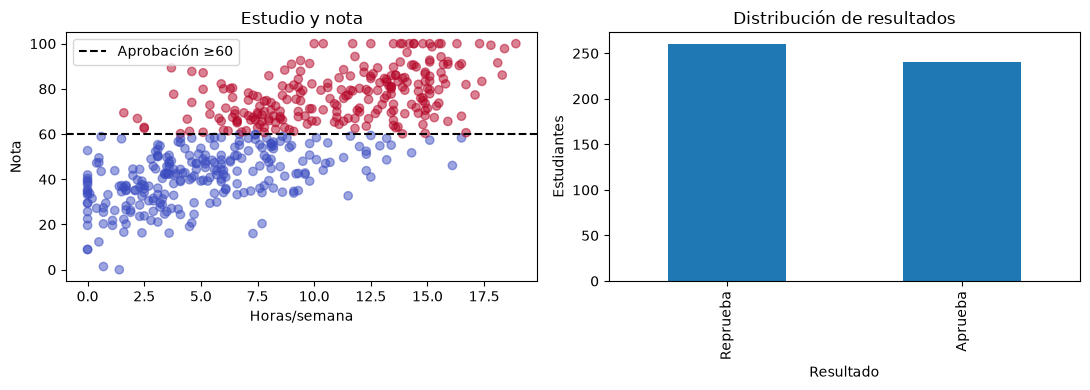

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(df['Horas_Estudio'], df['Nota'], c=df['Resultado'], cmap='coolwarm', alpha=.5)
ax[0].axhline(60, color='black', ls='--', label='Aprobación ≥60')
ax[0].set(xlabel='Horas/semana', ylabel='Nota', title='Estudio y nota')
ax[0].legend()
df['Resultado'].map({0:'Reprueba',1:'Aprueba'}).value_counts().plot.bar(ax=ax[1])
ax[1].set(title='Distribución de resultados', ylabel='Estudiantes', xlabel='Resultado')
plt.tight_layout()
plt.show()

**Para interpretar:** ¿qué tendencia observas entre las horas de estudio y la nota? ¿Están equilibradas las dos clases?

## Fase 2 — K-Means: agrupar estudiantes
K-Means es **no supervisado**: usa solo horas, asistencia y tareas. Estandarizamos porque estas variables están en escalas diferentes. Los grupos no equivalen automáticamente a aprobados/reprobados.


PERFILES DE 3 GRUPOS (promedios en unidades originales):


Horas_Estudio       Asistencia       Tareas_Entregadas      
                 mean count       mean count              mean count
Grupo_3                                                             
0                3.17   167      45.79   167             40.33   167
1               13.57   157      86.75   157             86.60   157
2                7.58   176      72.04   176             68.64   176

Tasa de aprobación por grupo (solo para interpretar; no usada al agrupar):


Grupo_3
0    0.042
1    0.911
2    0.511
Name: Proporción aprobada, dtype: float64


PERFILES DE 4 GRUPOS (promedios en unidades originales):


Horas_Estudio       Asistencia       Tareas_Entregadas      
                 mean count       mean count              mean count
Grupo_4                                                             
0               13.88   147      86.74   147             86.31   147
1                3.02   162      45.46   162             40.28   162
2                8.22   112      66.70   112             60.58   112
3                6.87    79      80.53    79             81.21    79

Tasa de aprobación por grupo (solo para interpretar; no usada al agrupar):


Grupo_4
0    0.905
1    0.031
2    0.473
3    0.620
Name: Proporción aprobada, dtype: float64

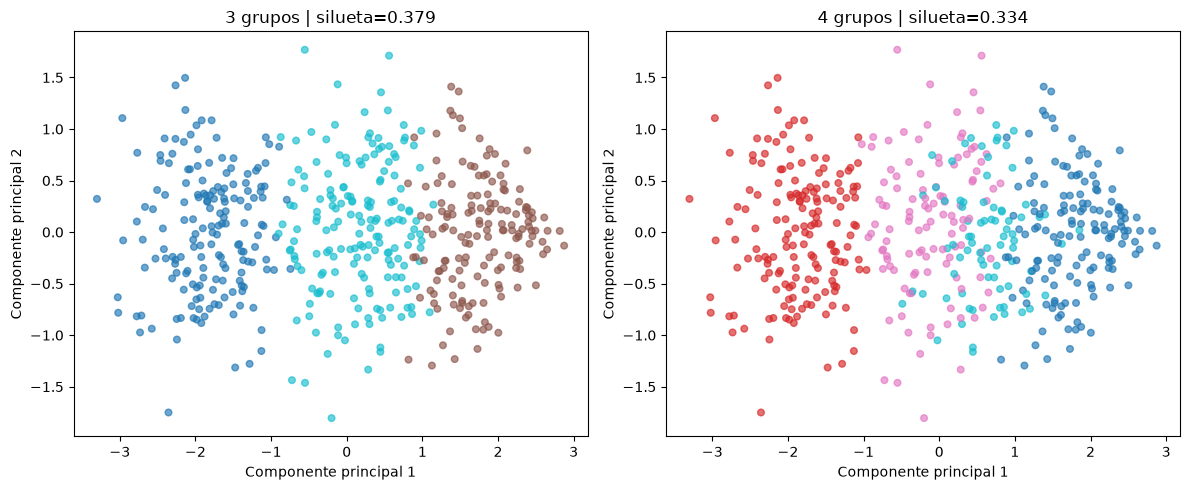

Comparación silueta (más alto generalmente indica grupos más definidos): {3: 0.379, 4: 0.334}


In [3]:
variables = ['Horas_Estudio', 'Asistencia', 'Tareas_Entregadas']
X = df[variables]
escalador_cluster = StandardScaler()
X_cluster = escalador_cluster.fit_transform(X)

# PCA es únicamente para representar 3 variables en dos ejes visuales
pca = PCA(n_components=2, random_state=SEED)
X_2d = pca.fit_transform(X_cluster)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
resumen_grupos = {}
for ax, grupos in zip(axes, [3, 4]):
    km = KMeans(n_clusters=grupos, random_state=SEED, n_init=10)
    etiquetas = km.fit_predict(X_cluster)
    df[f'Grupo_{grupos}'] = etiquetas
    sil = silhouette_score(X_cluster, etiquetas)
    resumen_grupos[grupos] = {'modelo': km, 'silueta': sil}
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=etiquetas, cmap='tab10', alpha=.65, s=23)
    ax.set(title=f'{grupos} grupos | silueta={sil:.3f}', xlabel='Componente principal 1', ylabel='Componente principal 2')
    print(f'\nPERFILES DE {grupos} GRUPOS (promedios en unidades originales):')
    display(df.groupby(f'Grupo_{grupos}')[variables].agg(['mean', 'count']).round(2))
    print('Tasa de aprobación por grupo (solo para interpretar; no usada al agrupar):')
    display(df.groupby(f'Grupo_{grupos}')['Resultado'].mean().round(3).rename('Proporción aprobada'))
plt.tight_layout()
plt.show()
print('Comparación silueta (más alto generalmente indica grupos más definidos):',
      {k: round(v['silueta'],3) for k,v in resumen_grupos.items()})

**Para interpretar:** asigna nombres descriptivos a cada grupo (por ejemplo, hábitos bajos/medios/altos) usando los **promedios reales de la tabla**, no el número de grupo. Contrasta tres contra cuatro grupos: ¿el cuarto separa un perfil útil o fragmenta otro? El puntaje de silueta es una ayuda, no una prueba absoluta.

## Fase 3 — KNN: predecir aprobar/reprobar
KNN es **supervisado**: aprende de ejemplos cuyos resultados ya conocemos. Dividimos 75 % entrenamiento (375) y 25 % prueba (125). Usamos división estratificada y ajustamos el escalador **solo** con entrenamiento para evitar fuga de información.

Entrenamiento: 375 Prueba: 125
Exactitud KNN k=5: 0.816
              precision    recall  f1-score   support

    Reprueba       0.85      0.78      0.82        65
     Aprueba       0.78      0.85      0.82        60

    accuracy                           0.82       125
   macro avg       0.82      0.82      0.82       125
weighted avg       0.82      0.82      0.82       125



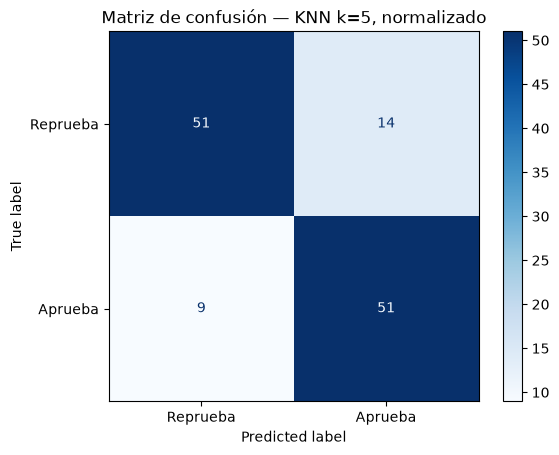

In [4]:
y = df['Resultado']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
print('Entrenamiento:', X_train.shape[0], 'Prueba:', X_test.shape[0])

modelo_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
modelo_knn.fit(X_train, y_train)
pred_5 = modelo_knn.predict(X_test)
print('Exactitud KNN k=5:', round(accuracy_score(y_test, pred_5), 4))
print(classification_report(y_test, pred_5, target_names=['Reprueba','Aprueba'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred_5, display_labels=['Reprueba', 'Aprueba'], cmap='Blues')
plt.title('Matriz de confusión — KNN k=5, normalizado')
plt.show()

**Para interpretar:** precisión global (accuracy) = predicciones correctas / 125. Revisa además errores por clase en la matriz de confusión; la exactitud sola puede ocultar problemas si hay más aprobados que reprobados.

## Fase 4 — Experimentación: valores de k y normalización
Probamos **k = 1, 3, 5, 7, 11, 15, 21**. Mantendremos el mismo conjunto de prueba. Atención: elegir el mejor k según la prueba y reportar esa misma exactitud como evaluación final es optimista; en un proyecto real se usa una validación adicional o validación cruzada sobre entrenamiento.

,k,Exactitud_normalizado,Exactitud_sin_normalizar
0,1,0.808,0.776
1,3,0.800,0.784
2,5,0.816,0.776
3,7,0.800,0.808
4,11,0.800,0.800
5,15,0.792,0.824
6,21,0.792,0.808


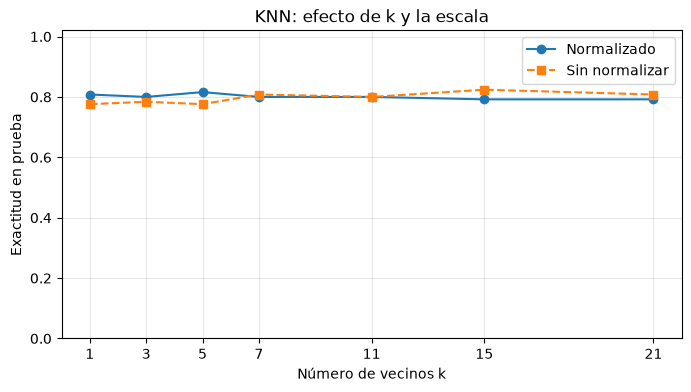

Mejor k normalizado en esta comparación exploratoria: 5


In [5]:
valores_k = [1, 3, 5, 7, 11, 15, 21]
filas = []
for k in valores_k:
    con_escala = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    sin_escala = KNeighborsClassifier(n_neighbors=k)
    con_escala.fit(X_train, y_train)
    sin_escala.fit(X_train, y_train)
    filas.append({
        'k': k,
        'Exactitud_normalizado': accuracy_score(y_test, con_escala.predict(X_test)),
        'Exactitud_sin_normalizar': accuracy_score(y_test, sin_escala.predict(X_test))
    })
comparacion = pd.DataFrame(filas)
display(comparacion.round(4))
plt.figure(figsize=(8, 4))
plt.plot(comparacion['k'], comparacion['Exactitud_normalizado'], 'o-', label='Normalizado')
plt.plot(comparacion['k'], comparacion['Exactitud_sin_normalizar'], 's--', label='Sin normalizar')
plt.xticks(valores_k)
plt.xlabel('Número de vecinos k')
plt.ylabel('Exactitud en prueba')
plt.title('KNN: efecto de k y la escala')
plt.ylim(0, 1.02)
plt.legend()
plt.grid(alpha=.3)
plt.show()
print('Mejor k normalizado en esta comparación exploratoria:',
      int(comparacion.loc[comparacion['Exactitud_normalizado'].idxmax(), 'k']))

**Para interpretar:** con k pequeño, KNN puede reaccionar a casos atípicos; con k grande, suaviza fronteras y puede perder detalles. Sin normalizar, diferencias grandes en asistencia y tareas pueden dominar las distancias sobre horas de estudio. Observa la tabla: la magnitud del cambio depende de los datos y no siempre mejora al normalizar.

## Fase 5 — Desafío final y limitaciones
Ejemplo: 4 horas de estudio por semana, 55 % de asistencia y 50 % de tareas. Para mantener la evaluación consistente, usamos el modelo de k=5 definido antes, sin seleccionarlo con el conjunto de prueba.

In [6]:
nuevo = pd.DataFrame([{
    'Horas_Estudio': 4.0, 'Asistencia': 55.0, 'Tareas_Entregadas': 50.0
}])
pronostico = int(modelo_knn.predict(nuevo)[0])
probabilidades = modelo_knn.predict_proba(nuevo)[0]
print('Predicción:', 'APRUEBA' if pronostico == 1 else 'REPRUEBA')
print(f'Proporción de vecinos que aprueban (k=5): {probabilidades[1]:.1%}')
print('IMPORTANTE: esta proporción de vecinos no es una probabilidad calibrada.')

Predicción: REPRUEBA
Proporción de vecinos que aprueban (k=5): 0.0%
IMPORTANTE: esta proporción de vecinos no es una probabilidad calibrada.


Conclusiones y análisis de resultados

1. K-Means: agrupación de estudiantes

Al trabajar con **3** **grupos**, pudimos identificar tres perfiles de estudiantes según sus hábitos académicos. El primero presentó menos horas de estudio, menor asistencia y menos tareas entregadas. El segundo mostró valores intermedios y el tercero presentó mejores resultados en estos tres aspectos.

Cuando utilizamos **4** **grupos**, el perfil intermedio se dividió en dos grupos con algunas diferencias en sus hábitos, principalmente en la asistencia y la entrega de tareas.

Al comparar los índices de silueta, obtuvimos **0.379** para 3 grupos y **0.334** para 4 grupos. Esto nos indica que trabajar con tres grupos permitió una mejor separación de los datos. Por lo tanto, consideramos que esta opción representa mejor los perfiles encontrados.

2. KNN: predicción de aprobación o reprobación

Al utilizar KNN con k=5 y datos normalizados, obtuvimos una exactitud del 81.6 %, lo que significa que el modelo acertó en 102 de los 125 casos evaluados.

En la matriz de confusión observamos que identificó correctamente a 51 estudiantes que reprobaron y 51 que aprobaron. Sin embargo, también cometió 23 errores: en 14 casos indicó que un estudiante aprobaría cuando realmente reprobó, y en otros 9 indicó que reprobaría cuando sí había aprobado.

Esto demuestra que el modelo logró reconocer varios patrones relacionados con los hábitos académicos, aunque todavía presentó algunas equivocaciones.

3. Experimentación y normalización

Al comparar los resultados de k=5, encontramos que el modelo normalizado obtuvo una exactitud del 81.6 %, mientras que el modelo sin normalizar alcanzó un 77.6 %.

Esto se debe a que KNN trabaja calculando distancias entre los datos. Como las horas de estudio, la asistencia y las tareas tienen diferentes escalas, normalizarlas ayuda a que ninguna variable tenga una influencia mayor solamente por sus valores numéricos.

También comprobamos que normalizar no siempre produce mejores resultados. Por ejemplo, con k=15, el modelo sin normalizar obtuvo un 82.4 %, frente al 79.2 % del modelo normalizado. Por eso, es importante comparar los resultados antes de decidir qué configuración funciona mejor.

4. Desafío final: predicción de un estudiante

Para el ejemplo de un estudiante que estudia 4 horas a la semana, tiene un 55 % de asistencia y ha entregado un 50 % de sus tareas, el modelo predijo que REPROBARÁ.

Al revisar sus cinco vecinos más cercanos, encontramos que ninguno pertenecía a la categoría de aprobados. Esto explica el resultado obtenido por el programa.

Sin embargo, esta predicción no significa que el estudiante necesariamente vaya a reprobar, ya que los resultados dependen de los datos utilizados y existen otros factores que pueden influir en su rendimiento académico.

5. Diferencias entre K-Means y KNN

Durante el proyecto pudimos observar que ambos algoritmos trabajan de manera diferente.

K-Means permite organizar a los estudiantes en grupos según las semejanzas de sus hábitos académicos, sin utilizar previamente sus resultados de aprobación o reprobación.

En cambio, KNN utiliza datos de estudiantes cuyos resultados ya se conocen para clasificar a otros estudiantes según sus características y los vecinos más cercanos.

En otras palabras, K-Means nos ayuda a encontrar grupos con características similares, mientras que KNN nos permite realizar predicciones a partir de los datos existentes.

6. Conclusión general

Con este proyecto pudimos conocer cómo funcionan dos algoritmos de Machine Learning y cómo se pueden aplicar al análisis de los hábitos académicos.

Con K-Means logramos identificar diferentes perfiles de estudiantes según sus horas de estudio, asistencia y tareas entregadas. Por otra parte, KNN alcanzó una exactitud del 81.6 % al predecir los resultados de aprobación y reprobación.

Consideramos que estas herramientas pueden ser útiles para encontrar patrones y reconocer posibles dificultades en el rendimiento académico. Sin embargo, sus resultados deben tomarse como una referencia y no como una decisión definitiva, ya que el desempeño de un estudiante depende de muchos otros factores.